<a href="https://colab.research.google.com/github/EthanJF-Physics/MAT422/blob/main/MAT422HW9EthanF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt

### 3.4 Logistic regression

Logistic regression is a model that in its basic form uses a logistic function to model a binary dependent variable. It can be extended to several classes of events such as the classification of images. In this section, we illustrate the use of gradient descent on binary classification by logistic regression.

Given the input data is of the form $\{(\boldsymbol{\alpha}_i, b_i) : i = 1, \dots, n\}$ where $\boldsymbol{\alpha}_i \in \mathbb{R}^d$ are the features and $b_i \in \{0, 1\}$ is the label. As before, we use a matrix representation: $A \in \mathbb{R}^{n \times d}$ has rows $\boldsymbol{\alpha}_j^T, j = 1, \dots, n$, and $\mathbf{b} = (b_1, \dots, b_n)^T \in \{0, 1\}^n$. We wish to find a function of the features that approximates the probability of the label 1. For this purpose, we model the logit function of the probability of label 1 as a linear function of the features. Fig. 3.11 is the graph of the logit function.

For $\mathbf{x}, \boldsymbol{\alpha} \in \mathbb{R}^d$, let $p(\boldsymbol{\alpha}; \mathbf{x})$ be the probability of the output to be 1. We define

$$ \log \frac{p(\boldsymbol{\alpha}; \mathbf{x})}{1 - p(\boldsymbol{\alpha}; \mathbf{x})} = \boldsymbol{\alpha}^T \mathbf{x} $$

Here, $\boldsymbol{\alpha}^T \mathbf{x} = \sum x_i \alpha_i$ can be viewed as a regression problem, which seeks the best parameters ($\mathbf{x}$) with given data ($\boldsymbol{\alpha}$). Rearranging this expression gives

$$ p(\boldsymbol{\alpha}; \mathbf{x}) = \sigma(\boldsymbol{\alpha}^T \mathbf{x}) $$
where the sigmoid function is

$$ \sigma(t) = \frac{1}{1 + e^{-t}} $$

for $t \in \mathbb{R}$. To maximize the likelihood of the data, we assume the labels are independent given the features, which is given by

$$ \mathscr{L}(\mathbf{x}; A, \mathbf{b}) = \prod_{i=1}^n p(\boldsymbol{\alpha}_i; \mathbf{x})^{b_i}(1 - p(\boldsymbol{\alpha}_i; \mathbf{x}))^{1-b_i}. $$

Taking a logarithm, multiplying by $-1/n$ and substituting the sigmoid function, we want to minimize the cross-entropy loss:

$$ \ell(\mathbf{x}; A, \mathbf{b}) = -\frac{1}{n} \sum_{i=1}^n b_i \log(\sigma(\boldsymbol{\alpha}_i^T \mathbf{x})) - \frac{1}{n} \sum_{i=1}^n (1 - b_i) \log(1 - \sigma(\boldsymbol{\alpha}_i^T \mathbf{x})). $$

That is, we solve

$$ \min_{\mathbf{x} \in \mathbb{R}^d} \ell(\mathbf{x}; A, \mathbf{b}). $$

To use gradient descent, we need to compute the gradient of $\ell$. We use the chain rule and first compute the derivative of $\sigma$, which is

$$ \sigma'(t) = \frac{e^{-t}}{(1 + e^{-t})^2} = \frac{1}{1 + e^{-t}} \left( 1 - \frac{1}{1 + e^{-t}} \right) = \sigma(t)(1 - \sigma(t)). $$

It follows that $\sigma(t)$ satisfies the logistic differential equation. It arises in a variety of applications, including the modeling of population dynamics.

Here, it will be a convenient way to compute the gradient. Indeed observe that by the chain rule

$$ \nabla_{\mathbf{x}} \sigma(\boldsymbol{\alpha}^T \mathbf{x}) = \sigma(\boldsymbol{\alpha}^T \mathbf{x})(1 - \sigma(\boldsymbol{\alpha}^T \mathbf{x})) \boldsymbol{\alpha}, $$

where we use a subscript $\mathbf{x}$ to make it clear that the gradient is with respect to $\mathbf{x}$.

With the same approach, we have

$$ \begin{aligned} \nabla_{\mathbf{x}} \ell(\mathbf{x}; A, \mathbf{b}) &= -\frac{1}{n} \sum_{i=1}^n \frac{b_i}{\sigma(\boldsymbol{\alpha}_i^T \mathbf{x})} \nabla_{\mathbf{x}} \sigma(\boldsymbol{\alpha}_i^T \mathbf{x}) + \frac{1}{n} \sum_{i=1}^n \frac{1 - b_i}{1 - \sigma(\boldsymbol{\alpha}_i^T \mathbf{x})} \nabla_{\mathbf{x}} \sigma(\boldsymbol{\alpha}_i^T \mathbf{x}) \\ &= -\frac{1}{n} \sum_{i=1}^n \left( \frac{b_i}{\sigma(\boldsymbol{\alpha}_i^T \mathbf{x})} - \frac{1 - b_i}{1 - \sigma(\boldsymbol{\alpha}_i^T \mathbf{x})} \right) \sigma(\boldsymbol{\alpha}_i^T \mathbf{x})(1 - \sigma(\boldsymbol{\alpha}_i^T \mathbf{x})) \boldsymbol{\alpha}_i \\ &= -\frac{1}{n} \sum_{i=1}^n (b_i - \sigma(\boldsymbol{\alpha}_i^T \mathbf{x})) \boldsymbol{\alpha}_i. \end{aligned} $$

To compute the Hessian, we note that

$$ \nabla_{\mathbf{x}} (\sigma(\boldsymbol{\alpha}^T \mathbf{x}) \alpha_j) = \sigma(\boldsymbol{\alpha}^T \mathbf{x})(1 - \sigma(\boldsymbol{\alpha}^T \mathbf{x})) \boldsymbol{\alpha} \alpha_j, $$

so that

$$ \nabla_{\mathbf{x}} (\sigma(\boldsymbol{\alpha}^T \mathbf{x}) \boldsymbol{\alpha}) = \sigma(\boldsymbol{\alpha}^T \mathbf{x})(1 - \sigma(\boldsymbol{\alpha}^T \mathbf{x})) \boldsymbol{\alpha} \boldsymbol{\alpha}^T. $$

Thus

$$ \nabla_{\mathbf{x}}^2 \ell(\mathbf{x}; A, \mathbf{b}) = \frac{1}{n} \sum_{i=1}^n \sigma(\boldsymbol{\alpha}_i^T \mathbf{x})(1 - \sigma(\boldsymbol{\alpha}_i^T \mathbf{x})) \boldsymbol{\alpha}_i \boldsymbol{\alpha}_i^T, $$

where $\nabla_{\mathbf{x}}^2$ indicates the Hessian with respect to the $\mathbf{x}$ variables. Now each $\boldsymbol{\alpha}_i \boldsymbol{\alpha}_i^T$ is a symmetric matrix and PSD. As a result, the function $\ell(\mathbf{x}; A, \mathbf{b})$ is convex as a function of $\mathbf{x} \in \mathbb{R}^d$. We want to comment that convexity is one reason for working with the cross-entropy loss rather than the mean squared error.

To update the iteration formula: for step size $\beta$, one step of gradient descent is therefore

$$ \mathbf{x}^{k+1} = \mathbf{x}^k + \beta \frac{1}{n} \sum_{i=1}^n (b_i - \sigma(\boldsymbol{\alpha}_i^T \mathbf{x}^k)) \boldsymbol{\alpha}_i. $$

In stochastic gradient descent, a variant of gradient descent, we pick a sample $I$ uniformly at random in $\{1, \dots, n\}$ and update as follows:

$$ \mathbf{x}^{k+1} = \mathbf{x}^k + \beta (b_I - \sigma(\boldsymbol{\alpha}_I^T \mathbf{x}^k)) \boldsymbol{\alpha}_I. $$


BATCH GRADIENT DESCENT
Learned parameters: [ 0.27470476  2.00842454 -1.28031655]
Final cross-entropy loss: 0.4423
Training accuracy: 79.50%

STOCHASTIC GRADIENT DESCENT
Learned parameters: [ 0.08024924  1.65195427 -0.98301309]
Final cross-entropy loss: 0.4494
Training accuracy: 77.50%


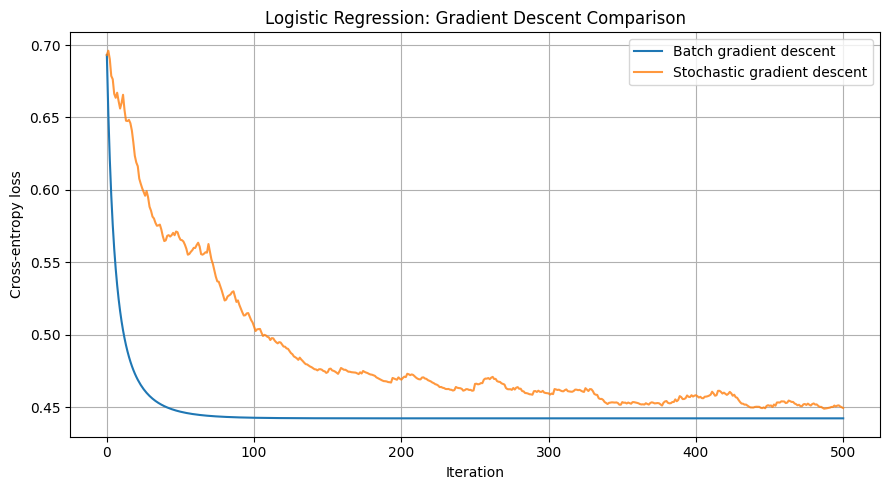

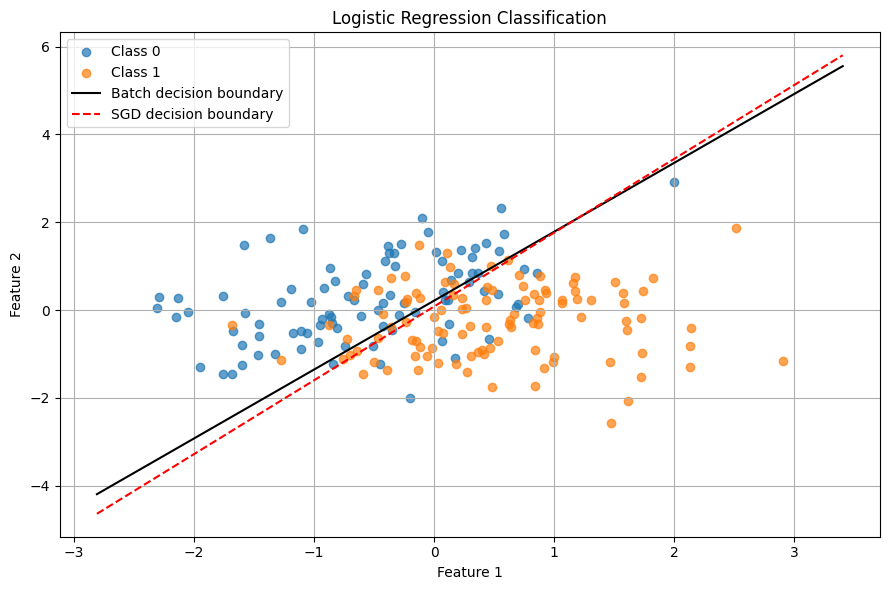

In [2]:
# Function and its analytical definitions
def sigmoid(t):
    t = np.clip(t, -500, 500)
    return 1.0 / (1.0 + np.exp(-t))
def cross_entropy_loss(A, b, x):
    n = A.shape[0]
    z = A @ x
    loss = np.mean(np.logaddexp(0, z) - b * z)
    return loss
def gradient(A, b, x):
    n = A.shape[0]
    p = sigmoid(A @ x)
    grad = (A.T @ (p - b)) / n
    return grad
def gradient_descent_step(A, b, x, beta):
    grad = gradient(A, b, x)
    x_next = x - beta * grad
    return x_next
def stochastic_gradient_descent_step(A, b, x, beta, rng):
    i = rng.integers(A.shape[0])
    alpha_i = A[i]
    b_i = b[i]
    p_i = sigmoid(alpha_i @ x)
    x_next = x + beta * (b_i - p_i) * alpha_i
    return x_next

# Evaluate the model
def evaluate(A, b, x):
    probabilities = sigmoid(A @ x)
    predictions = (probabilities >= 0.5).astype(int)
    loss = cross_entropy_loss(A, b, x)
    accuracy = np.mean(predictions == b)
    return loss, accuracy


# Dataset
rng = np.random.default_rng(42)
n = 200
X_raw = rng.normal(size=(n, 2))
# True parameters used to generate the labels
true_weights = np.array([2.0, -1.5])
true_bias = 0.3
# Generate probabilities and binary labels
true_probabilities = sigmoid(
    X_raw @ true_weights + true_bias
)
b = rng.binomial(1, true_probabilities)
# Add a column of ones for the intercept
A = np.column_stack([np.ones(n), X_raw])
# Initial parameters
x0 = np.zeros(A.shape[1])


# Batch gradient descent
beta_batch = 0.5
iterations = 500
x_batch = x0.copy()
batch_losses = []
for k in range(iterations):
    batch_losses.append(
        cross_entropy_loss(A, b, x_batch)
    )
    x_batch = gradient_descent_step(
        A, b, x_batch, beta_batch
    )
batch_losses.append(
    cross_entropy_loss(A, b, x_batch)
)
# Stochastic gradient descent
beta_sgd = 0.05
x_sgd = x0.copy()
sgd_losses = []
rng_sgd = np.random.default_rng(123)
for k in range(iterations):
    sgd_losses.append(
        cross_entropy_loss(A, b, x_sgd)
    )
    x_sgd = stochastic_gradient_descent_step(
        A, b, x_sgd, beta_sgd, rng_sgd
    )
sgd_losses.append(
    cross_entropy_loss(A, b, x_sgd)
)

# Evaluate both models
batch_loss, batch_accuracy = evaluate(A, b, x_batch)
sgd_loss, sgd_accuracy = evaluate(A, b, x_sgd)
print("=" * 50)
print("BATCH GRADIENT DESCENT")
print("=" * 50)
print("Learned parameters:", x_batch)
print(f"Final cross-entropy loss: {batch_loss:.4f}")
print(f"Training accuracy: {batch_accuracy:.2%}")
print("\n" + "=" * 50)
print("STOCHASTIC GRADIENT DESCENT")
print("=" * 50)
print("Learned parameters:", x_sgd)
print(f"Final cross-entropy loss: {sgd_loss:.4f}")
print(f"Training accuracy: {sgd_accuracy:.2%}")


# Plot the loss curves
plt.figure(figsize=(9, 5))
plt.plot(
    batch_losses,
    label="Batch gradient descent"
)
plt.plot(
    sgd_losses,
    label="Stochastic gradient descent",
    alpha=0.8
)
plt.xlabel("Iteration")
plt.ylabel("Cross-entropy loss")
plt.title("Logistic Regression: Gradient Descent Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Plot the classification results
plt.figure(figsize=(9, 6))
plt.scatter(
    X_raw[b == 0, 0],
    X_raw[b == 0, 1],
    label="Class 0",
    alpha=0.7
)
plt.scatter(
    X_raw[b == 1, 0],
    X_raw[b == 1, 1],
    label="Class 1",
    alpha=0.7
)
x1_values = np.linspace(
    X_raw[:, 0].min() - 0.5,
    X_raw[:, 0].max() + 0.5,
    200
)
# Batch gradient descent decision boundary
if abs(x_batch[2]) > 1e-12:
    x2_batch = (
        -(x_batch[0] + x_batch[1] * x1_values)
        / x_batch[2]
    )
    plt.plot(
        x1_values,
        x2_batch,
        color="black",
        label="Batch decision boundary"
    )
# SGD decision boundary
if abs(x_sgd[2]) > 1e-12:
    x2_sgd = (
        -(x_sgd[0] + x_sgd[1] * x1_values)
        / x_sgd[2]
    )
    plt.plot(
        x1_values,
        x2_sgd,
        color="red",
        linestyle="--",
        label="SGD decision boundary"
    )
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Logistic Regression Classification")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


CROSS-ENTROPY LOSS COMPARISON
Stable loss: 0.69314718
Alternate loss: 0.69314718
Absolute difference: 0.00000000e+00

GRADIENT COMPARISON
Vectorized gradient: [-0.04       -0.26023854  0.12659318]
Summation gradient: [-0.04       -0.26023854  0.12659318]
Maximum absolute difference: 1.11022302e-16

ALTERNATE BATCH GRADIENT DESCENT
Learned parameters: [ 0.27470476  2.00842454 -1.28031655]
Final cross-entropy loss: 0.4423
Training accuracy: 79.50%

ALTERNATE STOCHASTIC GRADIENT DESCENT
Learned parameters: [ 0.08024924  1.65195427 -0.98301309]
Final cross-entropy loss: 0.4494
Training accuracy: 77.50%


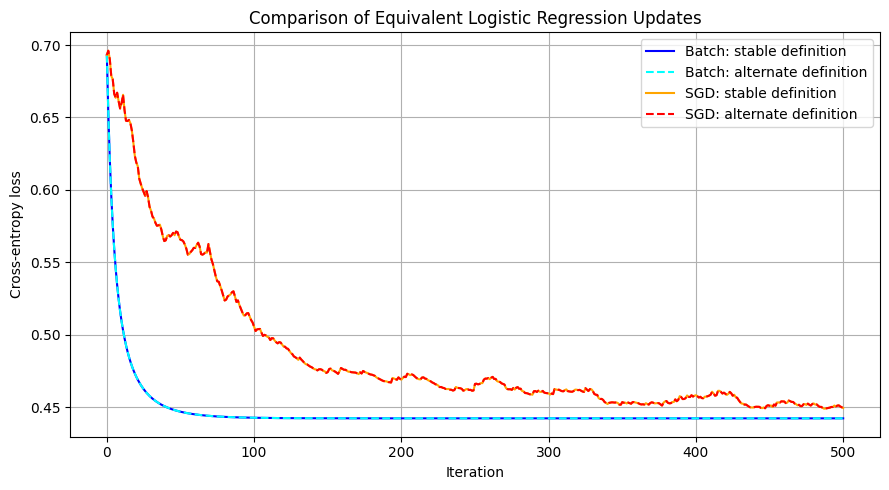


PARAMETER COMPARISON
Batch, stable:    [ 0.27470476  2.00842454 -1.28031655]
Batch, alternate: [ 0.27470476  2.00842454 -1.28031655]
SGD, stable:      [ 0.08024924  1.65195427 -0.98301309]
SGD, alternate:   [ 0.08024924  1.65195427 -0.98301309]


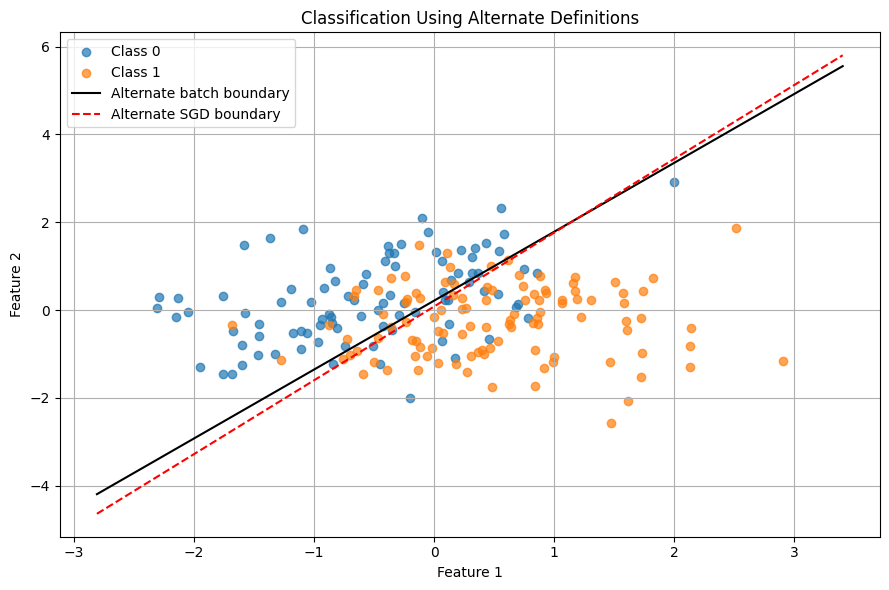

In [3]:
#Alternate version

# Alternate cross-entropy loss
def cross_entropy_loss_alternate(A, b, x):
    n = A.shape[0]
    probabilities = sigmoid(A @ x)
    # Protect logarithms against log(0)
    epsilon = 1e-12
    probabilities = np.clip(
        probabilities, epsilon, 1 - epsilon
    )

    loss = -np.mean(
        b * np.log(probabilities)
        + (1 - b) * np.log(1 - probabilities)
    )
    return loss


# Gradient using the summation definition
def gradient_alternate(A, b, x):
    n = A.shape[0]
    grad = np.zeros_like(x)
    probabilities = sigmoid(A @ x)
    for i in range(n):
        grad += (
            probabilities[i] - b[i]
        ) * A[i]
    grad = grad / n
    return grad


# Batch gradient descent using the residual definition
def gradient_descent_step_alternate(A, b, x, beta):
    n = A.shape[0]
    probabilities = sigmoid(A @ x)
    residuals = b - probabilities
    update = (A.T @ residuals) / n
    x_next = x + beta * update
    return x_next


# Stochastic gradient descent using the alternate definition
def stochastic_gradient_descent_step_alternate(
    A, b, x, beta, rng
):
    i = rng.integers(A.shape[0])
    alpha_i = A[i]
    b_i = b[i]
    p_i = sigmoid(alpha_i @ x)
    x_next = x + beta * (b_i - p_i) * alpha_i
    return x_next


# Dataset and initial parameters
# Use the same A, b, x0, and iterations from Section 1.

# Compare the two loss definitions
print("=" * 50)
print("CROSS-ENTROPY LOSS COMPARISON")
print("=" * 50)
loss_stable = cross_entropy_loss(A, b, x0)
loss_alternate = cross_entropy_loss_alternate(A, b, x0)
print(f"Stable loss: {loss_stable:.8f}")
print(f"Alternate loss: {loss_alternate:.8f}")
print(
    f"Absolute difference: "
    f"{abs(loss_stable - loss_alternate):.8e}"
)


# Compare the two gradient definitions
print("\n" + "=" * 50)
print("GRADIENT COMPARISON")
print("=" * 50)
grad_stable = gradient(A, b, x0)
grad_alternate = gradient_alternate(A, b, x0)
print("Vectorized gradient:", grad_stable)
print("Summation gradient:", grad_alternate)
print(
    f"Maximum absolute difference: "
    f"{np.max(np.abs(grad_stable - grad_alternate)):.8e}"
)


# Train using alternate batch gradient descent
beta_batch = 0.5
x_batch_alternate = x0.copy()
batch_alternate_losses = []
for k in range(iterations):
    batch_alternate_losses.append(
        cross_entropy_loss(A, b, x_batch_alternate)
    )
    x_batch_alternate = gradient_descent_step_alternate(
        A, b, x_batch_alternate, beta_batch
    )
batch_alternate_losses.append(
    cross_entropy_loss(A, b, x_batch_alternate)
)

# Train using alternate stochastic gradient descent
beta_sgd = 0.05
x_sgd_alternate = x0.copy()
sgd_alternate_losses = []
rng_sgd_alternate = np.random.default_rng(123)
for k in range(iterations):
    sgd_alternate_losses.append(
        cross_entropy_loss(A, b, x_sgd_alternate)
    )
    x_sgd_alternate = (
        stochastic_gradient_descent_step_alternate(
            A, b, x_sgd_alternate,
            beta_sgd, rng_sgd_alternate
        )
    )
sgd_alternate_losses.append(
    cross_entropy_loss(A, b, x_sgd_alternate)
)

# Evaluate the alternate models
batch_alt_loss, batch_alt_accuracy = evaluate(
    A, b, x_batch_alternate
)
sgd_alt_loss, sgd_alt_accuracy = evaluate(
    A, b, x_sgd_alternate
)
print("\n" + "=" * 50)
print("ALTERNATE BATCH GRADIENT DESCENT")
print("=" * 50)
print("Learned parameters:", x_batch_alternate)
print(f"Final cross-entropy loss: {batch_alt_loss:.4f}")
print(f"Training accuracy: {batch_alt_accuracy:.2%}")
print("\n" + "=" * 50)
print("ALTERNATE STOCHASTIC GRADIENT DESCENT")
print("=" * 50)
print("Learned parameters:", x_sgd_alternate)
print(f"Final cross-entropy loss: {sgd_alt_loss:.4f}")
print(f"Training accuracy: {sgd_alt_accuracy:.2%}")


# Plot the loss curves for both definitions
plt.figure(figsize=(9, 5))
plt.plot(
    batch_losses,
    label="Batch: stable definition",
    color="blue"
)
plt.plot(
    batch_alternate_losses,
    label="Batch: alternate definition",
    linestyle="--",
    color="cyan"
)
plt.plot(
    sgd_losses,
    label="SGD: stable definition",
    color="orange"
)
plt.plot(
    sgd_alternate_losses,
    label="SGD: alternate definition",
    linestyle="--",
    color="red"
)
plt.xlabel("Iteration")
plt.ylabel("Cross-entropy loss")
plt.title("Comparison of Equivalent Logistic Regression Updates")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Compare learned parameters
print("\n" + "=" * 50)
print("PARAMETER COMPARISON")
print("=" * 50)
print("Batch, stable:   ", x_batch)
print("Batch, alternate:", x_batch_alternate)
print("SGD, stable:     ", x_sgd)
print("SGD, alternate:  ", x_sgd_alternate)


# Plot the alternate classification boundaries
plt.figure(figsize=(9, 6))
plt.scatter(
    X_raw[b == 0, 0],
    X_raw[b == 0, 1],
    label="Class 0",
    alpha=0.7
)
plt.scatter(
    X_raw[b == 1, 0],
    X_raw[b == 1, 1],
    label="Class 1",
    alpha=0.7
)
x1_values = np.linspace(
    X_raw[:, 0].min() - 0.5,
    X_raw[:, 0].max() + 0.5,
    200
)
# Alternate batch decision boundary
if abs(x_batch_alternate[2]) > 1e-12:
    x2_batch_alternate = -(
        x_batch_alternate[0]
        + x_batch_alternate[1] * x1_values
    ) / x_batch_alternate[2]

    plt.plot(
        x1_values,
        x2_batch_alternate,
        color="black",
        label="Alternate batch boundary"
    )
# Alternate SGD decision boundary
if abs(x_sgd_alternate[2]) > 1e-12:
    x2_sgd_alternate = -(
        x_sgd_alternate[0]
        + x_sgd_alternate[1] * x1_values
    ) / x_sgd_alternate[2]

    plt.plot(
        x1_values,
        x2_sgd_alternate,
        color="red",
        linestyle="--",
        label="Alternate SGD boundary"
    )
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Classification Using Alternate Definitions")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()